<a href="https://colab.research.google.com/github/Taheri1400/deep-learning-projects/blob/main/RNN_LSTM_GRU_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 dir=rtl align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پیاده‌سازی شبکه‌های عصبی بازگشتی در کراس
</font>
</h1>


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
هدف مدل در این مسئله دریافت یک رشته به فرم "123456+789012" است و هدف مسئله به‌دست آوردن مقدار منطقی این معادله به صورت یک رشته می‌باشد. دقت کنید ورودی‌ها و خروجی مسئله رشته هستند و با آن‌ها مانند اعداد برخورد نمی‌شود.
</font>
</p>

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
وارد کردن کتابخانه‌های مورد نیاز</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
برای شروع پیاده‌سازی شبکه‌های عصبی بازگشتی، مانند تمامی پیاده‌سازی‌های دیگر ابتدا بخش `import` را اضافه می کنیم و کتابخانه‌های مورد نیاز را وارد می‌کنیم.
</font>
</p>

In [14]:
import numpy as np
from matplotlib import pyplot as plt

!pip install keras --upgrade

# Uncomment the above line if you don't have keras 3 installed
import keras
print(keras.__version__)

import os
os.environ["KERAS_BACKEND"] = "tensorflow"
from sklearn.model_selection import train_test_split

3.15.1


In [15]:
class colors:
    ok = '\033[92m'
    fail = '\033[91m'
    close = '\033[0m'

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
    بارگیری و بررسی و پیش‌پردازش داده‌ها
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
پس از وارد کردن کتابخانه‌ها دو فایل نامپای را می‌خوانیم که فایل `questions.npy` رشته‌های ورودی و فایل  `expected.npy` برچسب آن‌ها هستند. از این فایل به عنوان داده‌های ورودی استفاده می‌شود. </font>
</p>

In [16]:
questions = np.load('./questions.npy')
expected = np.load('./expected.npy')

پس از بارگیری داده‌ها ابتدا نگاهی کلی به آن‌ها می‌اندازیم، هرچند در این مسئله می‌دانیم اعداد نهایت شش رقمی هستند بنابراین رشته‌های ورودی نهایت ۱۳ کاراکتر خواهند داشت (شش کاراکتر برای عدد اول، شش کاراکتر برای عدد دوم و یک کاراکتر جمع +) و با جمع آن‌ها نهایت یک عدد هفت رقمی خواهیم داشت که نیاز به هفت کاراکتر دارد.

بنابراین یک متغیر برای نگه‌داری حداکثر تعداد رقم‌های اعداد به نام DIGITS تعریف کرده و کاراکتر‌های ممکن که شامل رقم‌ها ۰ تا ۹ و کاراکتر + و همچنین کاراکتر فاصله  می‌باشد را در متغیر chars نگه‌داری می‌کنیم.

In [17]:
print(questions)
print(expected)
DIGITS = 6
chars = '0123456789+ '

['4877+3539    ' '9+6037       ' '8+94         ' ... '7+6058       '
 '428212+51    ' '820+20       ']
['8416   ' '6046   ' '102    ' ... '6065   ' '428263 ' '840    ']


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تابع زیر عملیات رمزگذاری رشته‌ها به زبان مدل را انجام می‌دهد.
</font>
</p>

In [18]:
def encode(C, chars):
        char_indices = dict((c, i) for i, c in enumerate(chars))
        x = np.zeros((len(C), len(chars)))
        for i, c in enumerate(C):
            x[i, char_indices[c]] = 1
        return x

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تابع زیر رشته‌های رمزگذاری شده به زبان مدل را به رشته‌های قابل فهم برای انسان تبدیل می‌کند، به عبارت دیگر این تابع عملیات رمزگشایی را انجام می‌دهد.
 </font>

</p>

In [19]:
def decode(x, chars, calc_argmax = True):
    indices_char = dict((i, c) for i, c in enumerate(chars))
    if calc_argmax:
        x = x.argmax(axis=-1)
    return ''.join(indices_char[x] for x in x)

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
دو مثال از نحوه کار کرد توابع رمزگذار و رمزگشا را در قطعه کد زیر مشاهده می‌کنیم
 </font>

</p>

In [20]:
sample_index = 879953
x_sample = questions[sample_index]
encoded = encode(x_sample, chars)
print(f'{x_sample}\n encoded :\n {encoded}')

314959+685040
 encoded :
 [[0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [21]:
y_sample = expected[sample_index]
encoded = encode(y_sample, chars)
print(f'{y_sample}\n encoded :\n {encoded}')

999999 
 encoded :
 [[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تابع زیر عملیات رمزگذاری را برای تمامی مجموعه‌داده انجام می‌دهد.
 </font>

</p>

In [22]:
def vectorization(questions, expected ,DIGITS = DIGITS, chars = chars):
    MAXLEN = DIGITS + 1 + DIGITS
    x = np.zeros((len(questions), MAXLEN, len(chars)))
    y = np.zeros((len(questions), DIGITS + 1, len(chars)))
    for i, sentence in enumerate(questions):
        x[i] = encode(sentence, chars)
    for i, sentence in enumerate(expected):
        y[i] = encode(sentence, chars)
    return x, y

In [23]:
X, y = vectorization(questions, expected)
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=42)
print(f'Training Data: X- {x_train.shape} Y- {y_train.shape}')
print(f'Validation Data: X- {x_val.shape} Y- {y_val.shape}')

Training Data: X- (900000, 13, 12) Y- (900000, 7, 12)
Validation Data: X- (100000, 13, 12) Y- (100000, 7, 12)


<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
تعریف تابع برای آموزش مدل
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
از آنجایی که قصد داریم چند مدل مختلف را بررسی کنیم، ابتدا یک تابع برای روند اموزش تعریف می‌کنیم و مدل (که در ادامه آن را می‌سازیم)را به عنوان ورودی به این تابع می‌دهیم
</p>

In [24]:
BATCH_SIZE = 128

def fit_and_plot(model, BATCH_SIZE):
  train_acc = []
  valid_acc = []
  Iterations = 1
  epochs = 5

  for iteration in range(1, Iterations+1):
      print('-' * 50)
      print('Iteration', iteration)
      history = model.fit(x_train, y_train,
                          batch_size=BATCH_SIZE,
                          epochs=epochs,
                          validation_data=(x_val, y_val))

      train_acc.append(history.history['accuracy'])
      valid_acc.append(history.history['val_accuracy'])

      for i in range(10):
          ind = np.random.randint(0, len(x_val))
          rowx, rowy = x_val[np.array([ind])], y_val[np.array([ind])]
          q = decode(rowx[0], chars)
          correct = decode(rowy[0], chars)
          pred = model.predict(rowx)
          guess = decode(pred.argmax(-1)[0], chars ,calc_argmax=False)
          print('Q', q, end=' ')
          print('T', correct, end=' ')
          if correct == guess:
              print(colors.ok + '☑' + colors.close, end=' ')
          else:
              print(colors.fail + '☒' + colors.close, end=' ')
          print(guess)

  plt.plot( (np.array(train_acc)*100).flatten(), 'r')
  plt.plot( (np.array(valid_acc)*100).flatten(), 'b')
  plt.ylabel('Accuracy')
  plt.xlabel('Epoch')
  plt.legend(['Train', 'Validation'], loc='upper left')
  plt.show()

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
ساخت مدل
</font>
</h2>

<h3 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
شبکه‌ی بازگشتی ساده</font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تا اینجا به پیش‌پرداز مدل پرداختیم حال قصد داریم به ساخت مدلی که مسئله را برای ما حل کند بپردازیم. برای ساخت این مدل پس از تعریف لایه‌ی ورودی از یک لایه‌ی بازگشتی با تعداد ۶۴ نورون برای ساخت بخش اول شبکه، استفاده می‌کنیم، سپس با استفاده خروجی این لایه را با استفاده از لایه کپی کرده و به لایه‌ی بازگشتی بعدی را نیز با ۶۴ نورون و خروجی دنباله‌ای می‌دهیم. در نهایت با استفاده از یک لایه‌ی متراکم خروجی نهایی را مشخص می‌کنیم.
    
</p>

--------------------------------------------------
Iteration 1
Epoch 1/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 43s 5ms/step - accuracy: 0.4900 - loss: 1.3520 - val_accuracy: 0.5457 - val_loss: 1.1816
Epoch 2/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - accuracy: 0.5659 - loss: 1.1264 - val_accuracy: 0.5790 - val_loss: 1.0887
Epoch 3/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - accuracy: 0.5930 - loss: 1.0546 - val_accuracy: 0.5993 - val_loss: 1.0338
Epoch 4/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - accuracy: 0.6101 - loss: 1.0096 - val_accuracy: 0.6147 - val_loss: 1.0019
Epoch 5/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - accuracy: 0.6240 - loss: 0.9728 - val_accuracy: 0.6325 - val_loss: 0.9497
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 805ms/step
Q 0+522628      T 522628  ☒ 522635 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Q 39746+13540   T 53286   ☒ 71114  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Q 779644+260910 T 1040554 ☒ 111741 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Q 791509+37750  T 829259  

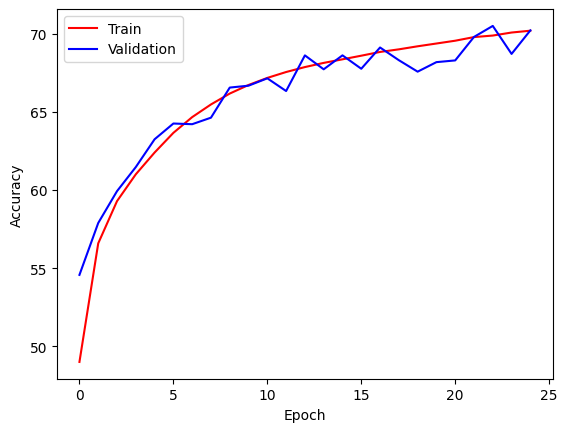

In [12]:
HIDDEN_SIZE = 64

model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(DIGITS*2 + 1, len(chars))))
model.add(keras.layers.SimpleRNN(HIDDEN_SIZE))
model.add(keras.layers.RepeatVector(DIGITS + 1))
model.add(keras.layers.SimpleRNN(HIDDEN_SIZE, return_sequences=True))
model.add(keras.layers.Dense(len(chars), activation='softmax'))
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

fit_and_plot(model, BATCH_SIZE)


<h3 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
حافظه‌ی طولانی کوتاه‌مدت</font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
با استفاده از معماری (تعداد واحد‌های آموزشی و ساختار) مدل قبلی ابن‌بار با استفاده از لایه حافظه‌ی طولانی کوتاه‌مدت شبکه را ساخته و آموزش می‌دهیم.
    
</p>

--------------------------------------------------
Iteration 1
Epoch 1/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 63s 8ms/step - accuracy: 0.4764 - loss: 1.3890 - val_accuracy: 0.5654 - val_loss: 1.1338
Epoch 2/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 58s 8ms/step - accuracy: 0.5998 - loss: 1.0393 - val_accuracy: 0.6210 - val_loss: 0.9808
Epoch 3/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 57s 8ms/step - accuracy: 0.6378 - loss: 0.9357 - val_accuracy: 0.6494 - val_loss: 0.9012
Epoch 4/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 57s 8ms/step - accuracy: 0.6613 - loss: 0.8694 - val_accuracy: 0.6718 - val_loss: 0.8397
Epoch 5/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 57s 8ms/step - accuracy: 0.6805 - loss: 0.8172 - val_accuracy: 0.6875 - val_loss: 0.7998
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step
Q 41300+5297    T 46597   ☒ 47667  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Q 3783+54       T 3837    ☒ 3838   
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Q 6548+3        T 6551    ☒ 6552   
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Q 78453+0       T 78453   

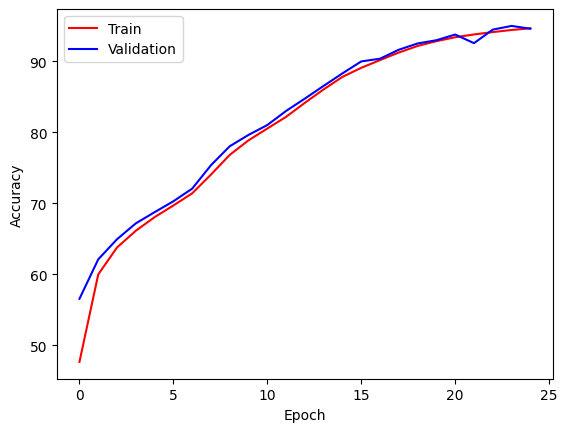

In [13]:
model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(DIGITS*2 + 1, len(chars))))
model.add(keras.layers.LSTM(HIDDEN_SIZE))
model.add(keras.layers.RepeatVector(DIGITS + 1))
model.add(keras.layers.LSTM(HIDDEN_SIZE, return_sequences=True))
model.add(keras.layers.Dense(len(chars), activation='softmax'))
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

fit_and_plot(model, BATCH_SIZE)


<h3 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
 واحد بازگشتی دروازه‌ای </font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
با استفاده از معماری (تعداد واحد‌های آموزشی و ساختار) مدل قبلی ابن‌بار با استفاده از لایه‌ی واحد بازگشتی دروازه‌ای را ساخته و آموزش می‌دهیم.
    
</p>

--------------------------------------------------
Iteration 1
Epoch 1/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 64s 9ms/step - accuracy: 0.4463 - loss: 1.4579 - val_accuracy: 0.5486 - val_loss: 1.1888
Epoch 2/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 58s 8ms/step - accuracy: 0.5885 - loss: 1.0703 - val_accuracy: 0.6141 - val_loss: 0.9977
Epoch 3/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 57s 8ms/step - accuracy: 0.6372 - loss: 0.9383 - val_accuracy: 0.6561 - val_loss: 0.8876
Epoch 4/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 56s 8ms/step - accuracy: 0.6713 - loss: 0.8498 - val_accuracy: 0.6787 - val_loss: 0.8280
Epoch 5/5
7032/7032 ━━━━━━━━━━━━━━━━━━━━ 56s 8ms/step - accuracy: 0.6967 - loss: 0.7838 - val_accuracy: 0.7086 - val_loss: 0.7540
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
Q 7073+16325    T 23398   ☒ 23355  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Q 81765+7       T 81772   ☒ 81770  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Q 35946+8827    T 44773   ☒ 44655  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Q 696+452       T 1148    

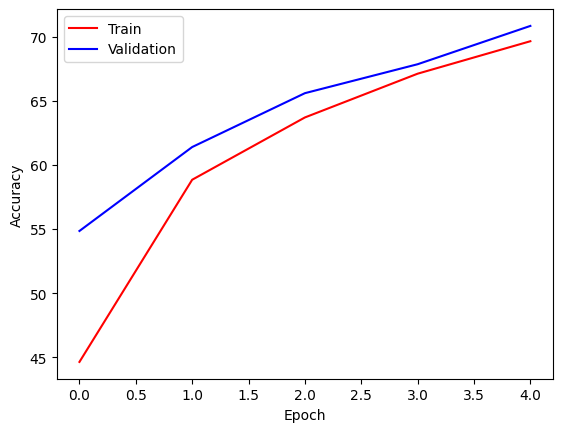

In [25]:
model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(DIGITS*2 + 1, len(chars))))
model.add(keras.layers.GRU(HIDDEN_SIZE))
model.add(keras.layers.RepeatVector(DIGITS + 1))
model.add(keras.layers.GRU(HIDDEN_SIZE, return_sequences=True))
model.add(keras.layers.Dense(len(chars), activation='softmax'))
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

fit_and_plot(model, BATCH_SIZE)